# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts** para Gemini, en el mismo Colab.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

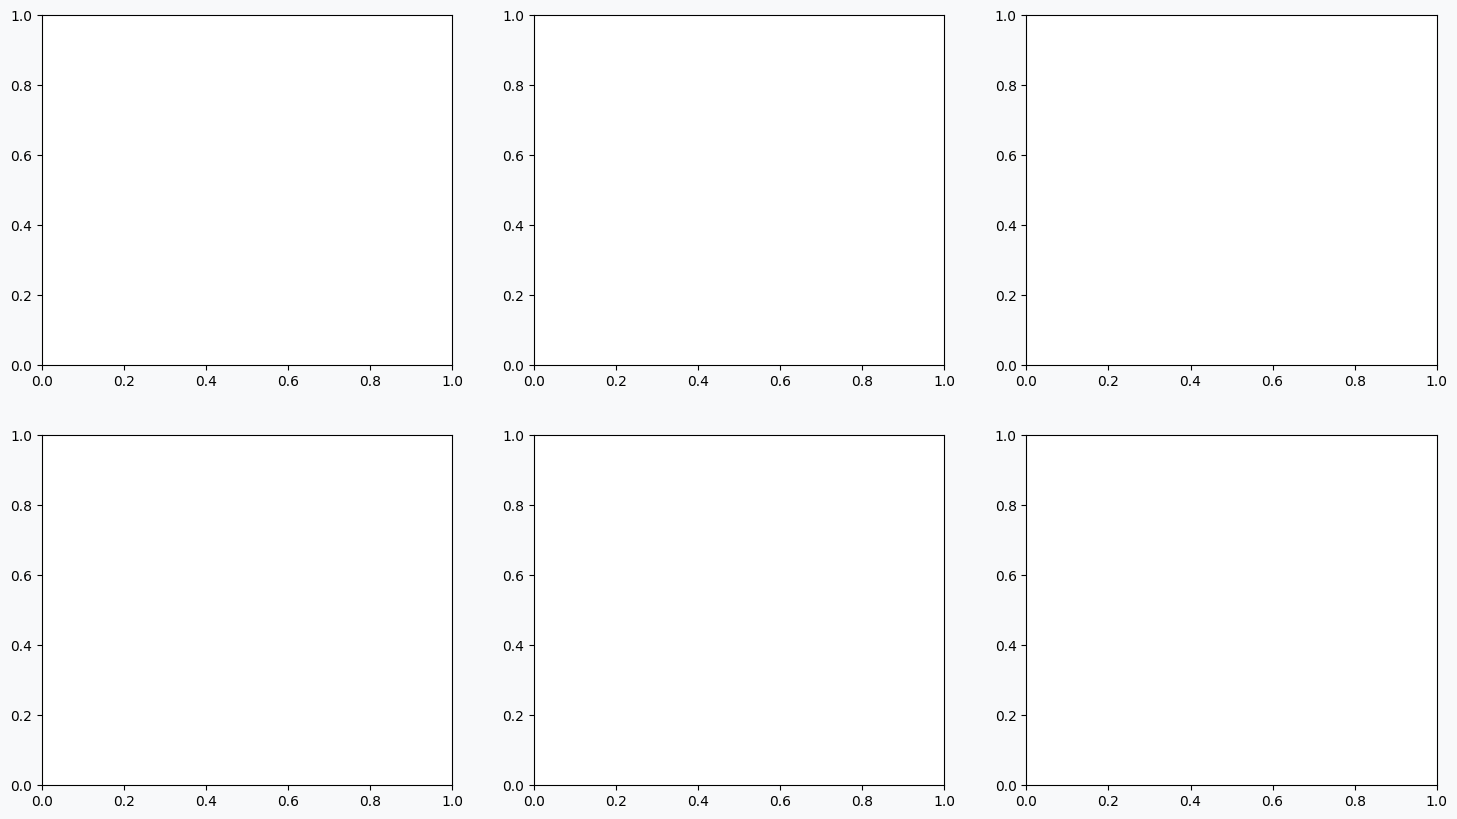

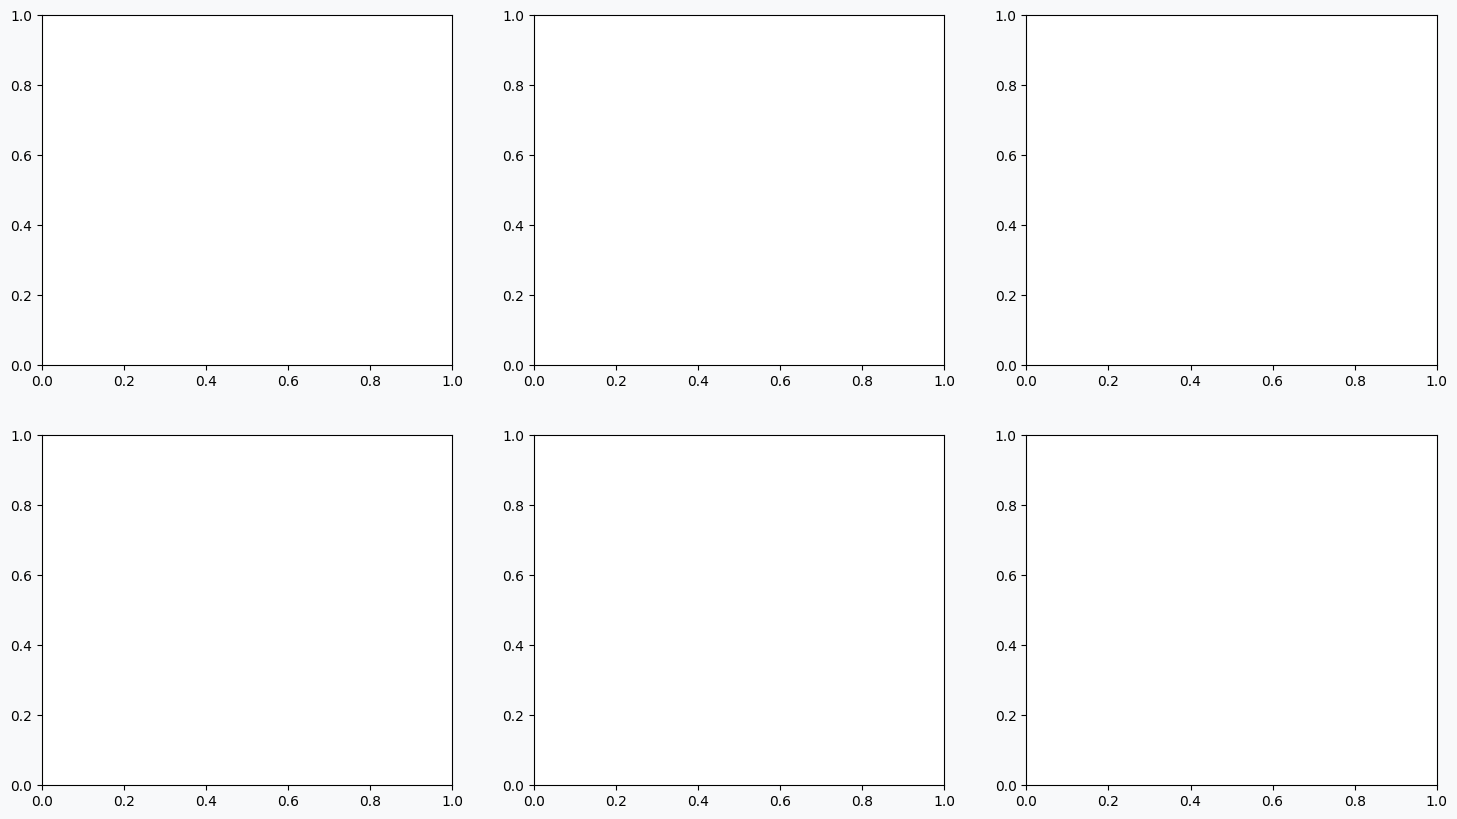

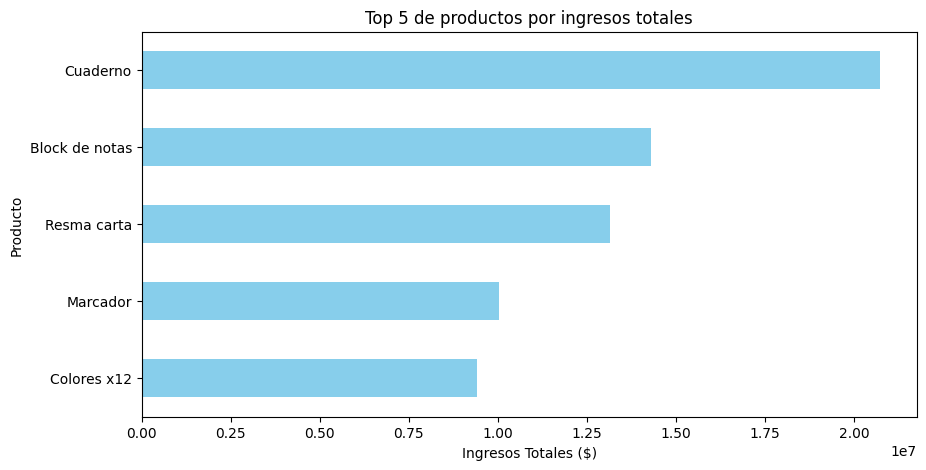

In [14]:
# Ejercicio 1
top_productos = df.groupby('producto')['total'].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 5))
top_productos.sort_values().plot.barh(color='skyblue')
plt.title('Top 5 de productos por ingresos totales')
plt.xlabel('Ingresos Totales ($)')
plt.ylabel('Producto')
plt.show()

### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

<Figure size 1000x500 with 0 Axes>

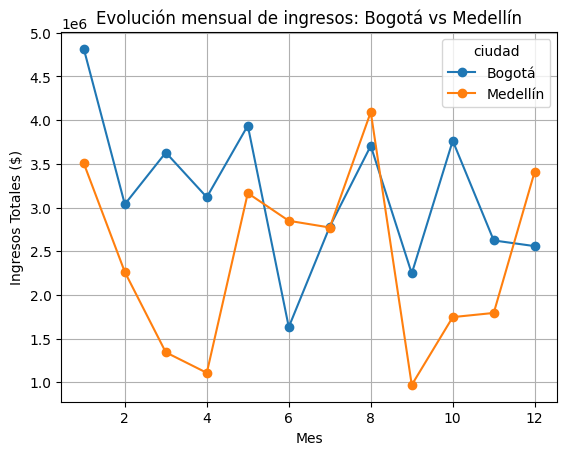

In [15]:
# Ejercicio 2
ing_mes_ciudad = df[df['ciudad'].isin(['Bogotá', 'Medellín'])].pivot_table(
    index='mes', columns='ciudad', values='total', aggfunc='sum'
)

plt.figure(figsize=(10, 5))
ing_mes_ciudad.plot.line(marker='o')
plt.title('Evolución mensual de ingresos: Bogotá vs Medellín')
plt.xlabel('Mes')
plt.ylabel('Ingresos Totales ($)')
plt.grid(True)
plt.show()

### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

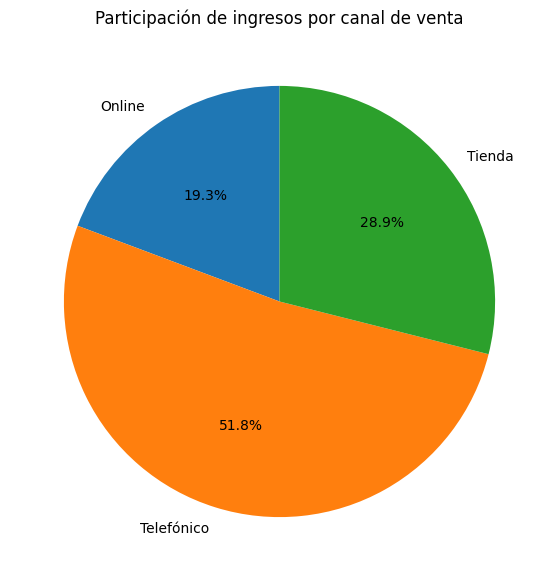

In [16]:
# Ejercicio 3
ing_canal = df.groupby('canal')['total'].sum()

plt.figure(figsize=(7, 7))
ing_canal.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Participación de ingresos por canal de venta')
plt.ylabel('')
plt.show()

### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

<Figure size 1000x600 with 0 Axes>

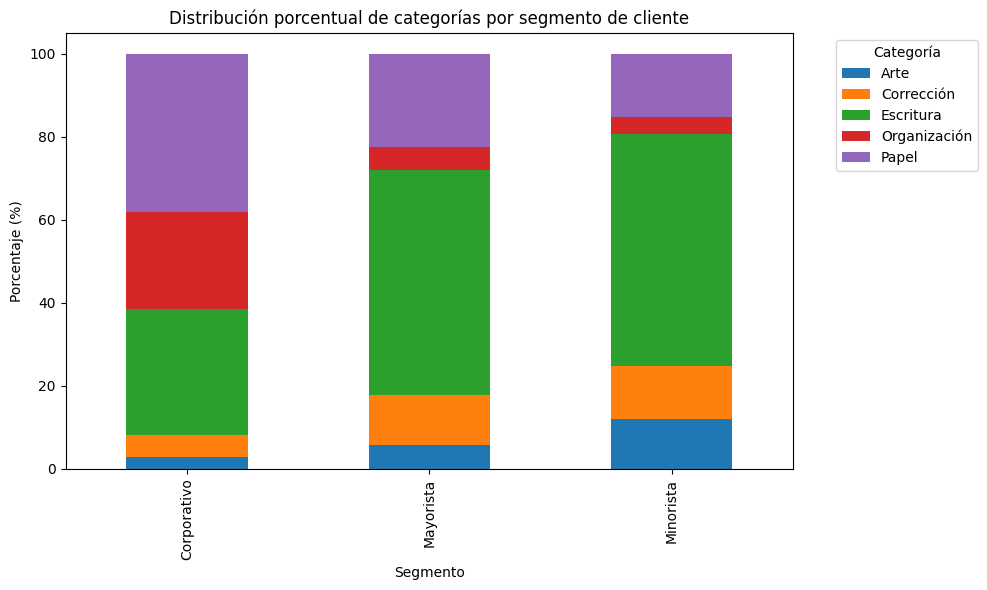

In [17]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(df['segmento'], df['categoria'], normalize='index') * 100

plt.figure(figsize=(10, 6))
tabla_seg_cat.plot.bar(stacked=True, figsize=(10, 6))
plt.title('Distribución porcentual de categorías por segmento de cliente')
plt.xlabel('Segmento')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Categoría', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

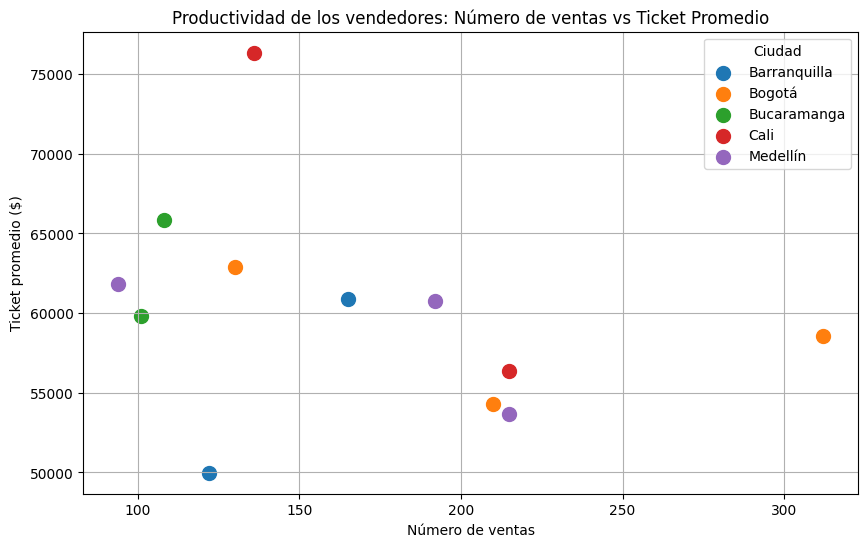

In [18]:
# Ejercicio 5

vend = df.groupby(['vendedor', 'ciudad']).agg(
    n_ventas=('id_venta', 'count'),
    ticket_prom=('total', 'mean')
).reset_index()

plt.figure(figsize=(10, 6))
for ciudad, grupo in vend.groupby('ciudad'):
    plt.scatter(grupo['n_ventas'], grupo['ticket_prom'], label=ciudad, s=100)

plt.title('Productividad de los vendedores: Número de ventas vs Ticket Promedio')
plt.xlabel('Número de ventas')
plt.ylabel('Ticket promedio ($)')
plt.legend(title='Ciudad')
plt.grid(True)
plt.show()

### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

<Figure size 1000x600 with 0 Axes>

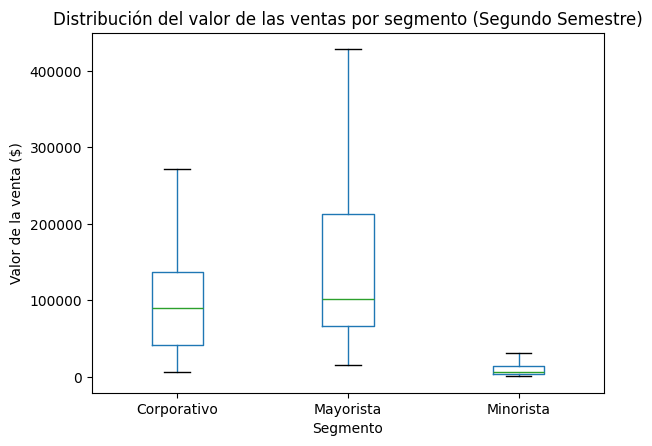

In [19]:
# Ejercicio 6
sem2 = df[df['mes'] >= 7]

plt.figure(figsize=(10, 6))
sem2.boxplot(column='total', by='segmento', showfliers=False, grid=False)
plt.title('Distribución del valor de las ventas por segmento (Segundo Semestre)')
plt.suptitle('') # Eliminar el supertítulo automático de pandas
plt.xlabel('Segmento')
plt.ylabel('Valor de la venta ($)')
plt.show()

---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [20]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))%%writefile figura_base.py
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Fila 0, Columna 0: Top 5 productos
top_productos.sort_values().plot.barh(ax=axs[0, 0], color='skyblue')
axs[0, 0].set_title('Top 5 de productos')
axs[0, 0].set_xlabel('Ingresos ($)')
axs[0, 0].set_ylabel('Producto')

# Fila 0, Columna 1: Bogotá vs Medellín
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker='o')
axs[0, 1].set_title('Ingresos: Bogotá vs Medellín')
axs[0, 1].set_xlabel('Mes')
axs[0, 1].set_ylabel('Ingresos ($)')
axs[0, 1].grid(True)

# Fila 0, Columna 2: Canales de venta (Pie)
ing_canal.plot.pie(ax=axs[0, 2], autopct='%1.1f%%', startangle=90)
axs[0, 2].set_title('Ingresos por Canal')
axs[0, 2].set_ylabel('')

# Fila 1, Columna 0: Segmento vs Categoría (Barras apiladas)
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True)
axs[1, 0].set_title('Categorías por Segmento (%)')
axs[1, 0].set_xlabel('Segmento')
axs[1, 0].set_ylabel('Porcentaje (%)')
axs[1, 0].legend(title='Categoría', fontsize='small')

# Fila 1, Columna 1: Productividad de vendedores (Dispersión)
for ciudad, grupo in vend.groupby('ciudad'):
    axs[1, 1].scatter(grupo['n_ventas'], grupo['ticket_prom'], label=ciudad, s=80)
axs[1, 1].set_title('Productividad de Vendedores')
axs[1, 1].set_xlabel('Número de ventas')
axs[1, 1].set_ylabel('Ticket promedio ($)')
axs[1, 1].legend(title='Ciudad', fontsize='small')
axs[1, 1].grid(True)

# Fila 1, Columna 2: Diagrama de cajas (Semestre 2)
sem2.boxplot(column='total', by='segmento', ax=axs[1, 2], showfliers=False, grid=False)
axs[1, 2].set_title('Ventas por Segmento (Semestre 2)')
axs[1, 2].set_xlabel('Segmento')
axs[1, 2].set_ylabel('Valor de venta ($)')

# Ajustes generales
fig.suptitle('Ventas de la cadena de papelerías 2025 - Dashboard', fontsize=18)
plt.tight_layout()
plt.show()

Overwriting figura_base.py


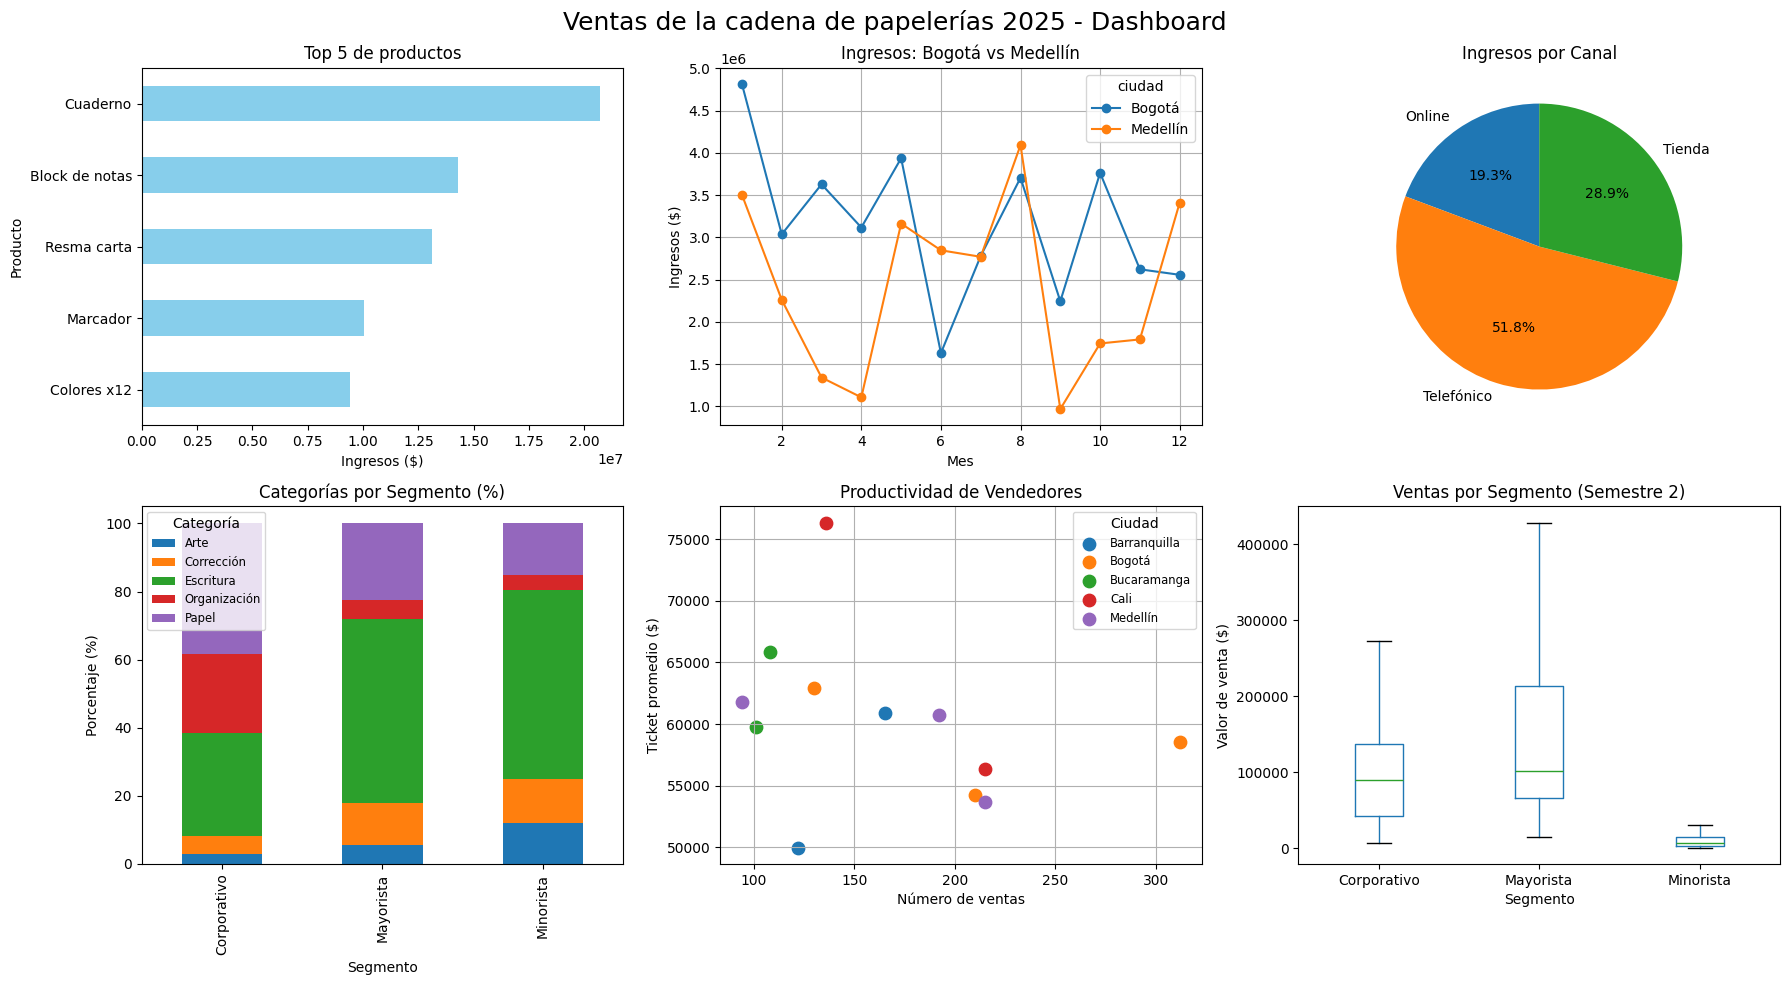

<Figure size 640x480 with 0 Axes>

In [21]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt y Gemini reescribe el código** de tu figura para que se vea profesional, casi como un dashboard.


### Herramientas *(ya están hechas)*
Ejecuta esta celda. Define dos funciones:

- **`embellecer(prompt, nombre)`**: envía tu prompt **junto con tu código de `figura_base.py`**, ejecuta el código nuevo que devuelve Gemini y muestra la figura. Cada versión queda guardada en `VERSIONES[nombre]`.
- **`mostrar(nombre)`**: vuelve a dibujar una versión guardada.

In [52]:
import re

VERSIONES = {}      # aquí se guarda el código de cada versión ("v1", "v2", ...)

REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual (puedes recalcular las tablas con el mismo código);
  cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def extraer_codigo(texto):
    """Devuelve el contenido del primer bloque de código ``` de la respuesta."""
    bloque = re.search(r"```(?:python)?\s*\n(.*?)```", texto, re.S)
    return bloque.group(1) if bloque else texto


def dibujar(codigo):
    """Ejecuta el código de una figura y la muestra."""
    import numpy as np
    plt.close("all")
    espacio = {"df": df, "pd": pd, "plt": plt, "np": np}
    exec(codigo, espacio)
    figura = espacio["fig"]
    display(figura)
    plt.close(figura)


def embellecer(prompt, nombre, modelo="gemini-flash-latest"):
    """Gemini reescribe tu figura según tu prompt; se ejecuta, se muestra y se guarda en VERSIONES."""
    codigo_actual = open("figura_base.py", encoding="utf-8").read()
    contenido = f"{prompt}\n\nEste es mi código actual:\n```python\n{codigo_actual}\n```{REGLAS_FIGURA}"
    respuesta = client.models.generate_content(model=modelo, contents=contenido)
    codigo = extraer_codigo(respuesta.text)
    try:
        dibujar(codigo)
    except Exception as e:
        print("❌ El código de Gemini falló:", type(e).__name__, e)
        print("Copia ese error en tu siguiente prompt y pídele que lo corrija.")
        return
    VERSIONES[nombre] = codigo
    print(f"✔ Versión '{nombre}' guardada")


def mostrar(nombre):
    """Vuelve a dibujar una versión guardada."""
    dibujar(VERSIONES[nombre])

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Mejora el código manteniendo su estructura y funcionalidad, pero optimizando el diseño visual de los gráficos para que tengan una apariencia más profesional y ejecutiva. Utiliza un fondo gris muy claro con paneles blancos y una paleta corporativa moderna, empleando tonos azules para los gráficos de barras y líneas, y colores variados y diferenciados para representar las categorías de productos y los canales de venta. Aplica una tipografía sans-serif, con títulos en negrita, alineados a la izquierda y de tamaño legible. Modifica los títulos de cada gráfico para que sean analíticos y expresen directamente los hallazgos más importantes de los datos, por ejemplo: "Cuadernos lideran los ingresos", "Bogotá supera a Medellín" o "El canal telefónico domina las ventas". Mejora el formato de los ejes y las etiquetas numéricas, incorporando separadores de miles en los valores monetarios y evitando la saturación de información. Elimina los bordes y marcos innecesarios, especialmente los superiores y derechos (spines), incorpora cuadrículas sutiles cuando faciliten la lectura y ajusta la ubicación de las leyendas para que no oculten los datos. Conserva toda la información y precisión de los datos originales, priorizando la claridad, la coherencia visual y una presentación ejecutiva que facilite la interpretación de los resultados comerciales de 2025 y la toma de decisiones estratégicas.

In [60]:

prompt_v1 = ""
PÚBLICO Y OBJETIVO: Presentación ejecutiva para la junta directiva de la cadena de papelerías, con el fin de evaluar el rendimiento comercial de 2025 y facilitar la toma de decisiones estratégicas.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro con paneles blancos y una paleta corporativa moderna que emplee tonos azules para los gráficos de barras y líneas, y colores variados y diferenciados para representar categorías y canales. Tipografía sans-serif.

TÍTULOS: Títulos analíticos en negrita, alineados a la izquierda y de tamaño legible, que expresen hallazgos clave como "Cuadernos lideran los ingresos", "Bogotá supera a Medellín" o "El canal telefónico domina las ventas".

EJES Y NÚMEROS: Formato mejorado en los ejes y etiquetas numéricas, incorporando separadores de miles en los valores monetarios y evitando la saturación de información.

LIMPIEZA VISUAL: Eliminación de bordes y marcos innecesarios (superiores y derechos), incorporación de cuadrículas sutiles para facilitar la lectura y ajuste de las leyendas para que no oculten los datos, conservando toda la precisión original.
""

embellecer(prompt_v1, "v1")

SyntaxError: invalid syntax (2258874403.py, line 2)

In [61]:
%%writefile figura_base.py
import pandas as pd
import matplotlib.pyplot as plt

# Ejercicio 7: Dashboard ejecutivo optimizado
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#f8f9fa')  # Fondo general gris muy claro

# 1. Fila 0, Columna 0: Top 5 productos
ax0 = axs[0, 0]
ax0.set_facecolor('#ffffff')
top_productos.sort_values().plot.barh(ax=ax0, color='#2b5c8f')
ax0.set_title('Cuadernos lideran los ingresos (Top 5)', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax0.set_xlabel('Ingresos Totales ($)', fontsize=10)
ax0.set_ylabel('Producto', fontsize=10)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)

# 2. Fila 0, Columna 1: Bogotá vs Medellín
ax1 = axs[0, 1]
ax1.set_facecolor('#ffffff')
ing_mes_ciudad.plot.line(ax=ax1, marker='o', linewidth=2, color=['#1f77b4', '#ff7f0e'])
ax1.set_title('Bogotá supera sistemáticamente a Medellín', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax1.set_xlabel('Mes del año', fontsize=10)
ax1.set_ylabel('Ingresos ($)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# 3. Fila 0, Columna 2: Canales de venta (Dona moderna)
ax2 = axs[0, 2]
ax2.set_facecolor('#ffffff')
ing_canal.plot.pie(ax=ax2, autopct='%1.1f%%', startangle=90, colors=['#4682b4', '#ff7f0e', '#2ca02c'],
                   wedgeprops=dict(width=0.4, edgecolor='w'))
ax2.set_title('El canal telefónico domina las ventas', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax2.set_ylabel('')

# 4. Fila 1, Columna 0: Segmento vs Categoría (Barras apiladas)
ax3 = axs[1, 0]
ax3.set_facecolor('#ffffff')
tabla_seg_cat.plot.bar(ax=ax3, stacked=True, colormap='tab10')
ax3.set_title('Escritura y Papel concentran la mayor demanda', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax3.set_xlabel('Segmento de cliente', fontsize=10)
ax3.set_ylabel('Porcentaje (%)', fontsize=10)
ax3.legend(title='Categoría', fontsize='x-small', loc='upper right', frameon=True)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.tick_params(axis='x', rotation=0)

# 5. Fila 1, Columna 1: Productividad de vendedores (Dispersión)
ax4 = axs[1, 1]
ax4.set_facecolor('#ffffff')
for ciudad, grupo in vend.groupby('ciudad'):
    ax4.scatter(grupo['n_ventas'], grupo['ticket_prom'], label=ciudad, s=90, alpha=0.8)
ax4.set_title('Mayor volumen no siempre implica mayor ticket', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax4.set_xlabel('Número de ventas', fontsize=10)
ax4.set_ylabel('Ticket promedio ($)', fontsize=10)
ax4.legend(title='Ciudad', fontsize='x-small', frameon=True)
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

# 6. Fila 1, Columna 2: Diagrama de cajas (Semestre 2)
ax5 = axs[1, 2]
ax5.set_facecolor('#ffffff')
sem2.boxplot(column='total', by='segmento', ax=ax5, showfliers=False, grid=False,
             boxprops=dict(color='#1f77b4', linewidth=1.5),
             medianprops=dict(color='#ff7f0e', linewidth=2))
ax5.set_title('Clientes corporativos presentan mayor valor de venta', fontsize=12, fontweight='bold', loc='left', color='#222222')
ax5.set_xlabel('Segmento', fontsize=10)
ax5.set_ylabel('Valor de venta ($)', fontsize=10)
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)

# Ajustes generales del dashboard
fig.suptitle('Dashboard Ejecutivo · Ventas de la Cadena de Papelerías 2025', fontsize=16, fontweight='bold', color='#111111', y=0.96)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Overwriting figura_base.py


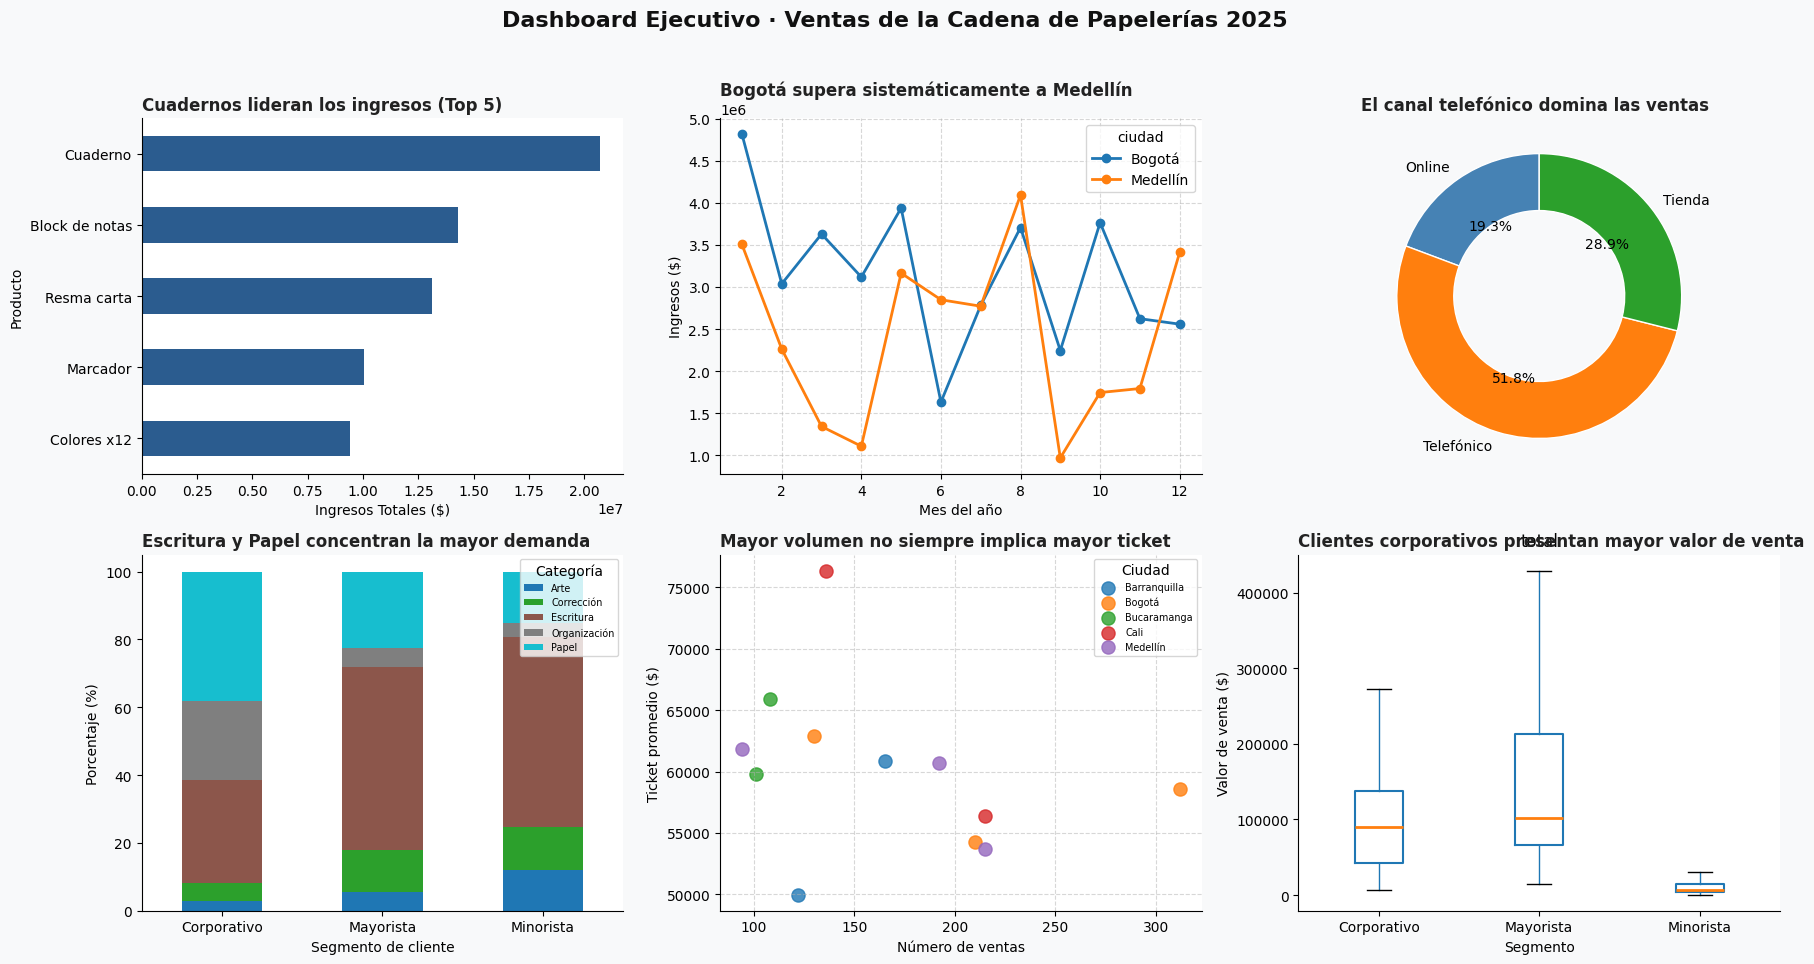

<Figure size 640x480 with 0 Axes>

In [62]:
%run -i figura_base.py

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (por ejemplo: otra paleta, letras más grandes, anotar el valor máximo del gráfico de líneas, cambiar el pie por una dona…). Es la **iteración de prompts** que vimos en clase.

**Ajustes:** Deja todos los datos de los gráficos en diferentes tonos de azules y verdesy deja mas separación entre cada grafica para que se vea mas ordenado. además Haz que el titulo sea mas notorio. Necesito que se vea muy profesional y ordenado.

In [58]:
prompt_v2 = "v2"
PÚBLICO Y OBJETIVO: Presentación ejecutiva y moderna para la junta directiva de la cadena de papelerías, buscando un diseño sumamente limpio y ordenado.

PALETA Y TIPOGRAFÍA: Utiliza exclusivamente una paleta elegante y coordinada basada únicamente en tonos de azules y verdes. Fondo gris muy claro con paneles blancos limpios y tipografía sans-serif.

TÍTULOS: Títulos grandes, llamativos y analíticos en negrita y alineados a la izquierda. Haz que el título principal de la figura sea mucho más notorio y grande.

EJES Y NÚMEROS: Formato de ejes limpios, separadores de miles en los valores monetarios y etiquetas claras sin saturación.

LIMPIEZA VISUAL Y ESPACIADO: Deja mucha más separación (espacio en blanco amplio) entre cada uno de los 6 gráficos para que el dashboard se vea ordenado, amplio y muy profesional. Elimina los bordes superiores y derechos innecesarios.
""

embellecer(prompt_v2, "v2")

SyntaxError: invalid syntax (3458715946.py, line 2)

In [63]:
%%writefile figura_base.py
import pandas as pd
import matplotlib.pyplot as plt

# Crear la figura con mayor separación (wspace y hspace) para que se vea muy ordenado
fig, axs = plt.subplots(2, 3, figsize=(20, 12))
fig.patch.set_facecolor('#f4f6f9')  # Fondo general gris muy claro y profesional
plt.subplots_adjust(wspace=0.35, hspace=0.40)

# Paleta exclusiva: Tonos azules, morados y verdes modernos y elegantes
AZUL_PROFUNDO = '#1b365d'
AZUL_CLARO = '#4a90e2'
MORADO_OSCURO = '#512b58'
MORADO_CLARO = '#8b78e6'
VERDE_MEDIO = '#2e8b57'
VERDE_CLARO = '#3cb371'

# 1. Fila 0, Columna 0: Top 5 productos (Azul profundo)
ax0 = axs[0, 0]
ax0.set_facecolor('#ffffff')
top_productos.sort_values().plot.barh(ax=ax0, color=AZUL_PROFUNDO)
ax0.set_title('Cuadernos lideran los ingresos (Top 5)', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax0.set_xlabel('Ingresos Totales ($)', fontsize=10)
ax0.set_ylabel('Producto', fontsize=10)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)

# 2. Fila 0, Columna 1: Bogotá vs Medellín (Azul y Morado)
ax1 = axs[0, 1]
ax1.set_facecolor('#ffffff')
ing_mes_ciudad.plot.line(ax=ax1, marker='o', linewidth=2.5, color=[AZUL_CLARO, MORADO_CLARO])
ax1.set_title('Bogotá supera sistemáticamente a Medellín', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax1.set_xlabel('Mes del año', fontsize=10)
ax1.set_ylabel('Ingresos ($)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# 3. Fila 0, Columna 2: Canales de venta (Dona en Azul, Morado y Verde)
ax2 = axs[0, 2]
ax2.set_facecolor('#ffffff')
ing_canal.plot.pie(ax=ax2, autopct='%1.1f%%', startangle=90,
                   colors=[AZUL_PROFUNDO, MORADO_OSCURO, VERDE_MEDIO],
                   wedgeprops=dict(width=0.45, edgecolor='w'))
ax2.set_title('El canal telefónico domina las ventas', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax2.set_ylabel('')

# 4. Fila 1, Columna 0: Segmento vs Categoría (Barras apiladas con colormap de tonos verdes/azules/morados)
ax3 = axs[1, 0]
ax3.set_facecolor('#ffffff')
tabla_seg_cat.plot.bar(ax=ax3, stacked=True, colormap='viridis')
ax3.set_title('Escritura y Papel concentran la mayor demanda', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax3.set_xlabel('Segmento de cliente', fontsize=10)
ax3.set_ylabel('Porcentaje (%)', fontsize=10)
ax3.legend(title='Categoría', fontsize='x-small', loc='upper right', frameon=True)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.tick_params(axis='x', rotation=0)

# 5. Fila 1, Columna 1: Productividad de vendedores (Dispersión con colores verde, morado y azul)
ax4 = axs[1, 1]
ax4.set_facecolor('#ffffff')
colores_ciudades = [AZUL_PROFUNDO, MORADO_OSCURO, VERDE_MEDIO, AZUL_CLARO, MORADO_CLARO]
for i, (ciudad, grupo) in enumerate(vend.groupby('ciudad')):
    ax4.scatter(grupo['n_ventas'], grupo['ticket_prom'], label=ciudad, s=90, alpha=0.85, color=colores_ciudades[i % len(colores_ciudades)])
ax4.set_title('Mayor volumen no siempre implica mayor ticket', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax4.set_xlabel('Número de ventas', fontsize=10)
ax4.set_ylabel('Ticket promedio ($)', fontsize=10)
ax4.legend(title='Ciudad', fontsize='x-small', frameon=True)
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

# 6. Fila 1, Columna 2: Diagrama de cajas (Semestre 2 en tonos morados y azules)
ax5 = axs[1, 2]
ax5.set_facecolor('#ffffff')
sem2.boxplot(column='total', by='segmento', ax=ax5, showfliers=False, grid=False,
             boxprops=dict(color=MORADO_OSCURO, linewidth=1.5),
             medianprops=dict(color=AZUL_CLARO, linewidth=2.5))
ax5.set_title('Clientes corporativos presentan mayor valor de venta', fontsize=13, fontweight='bold', loc='left', color='#111111')
ax5.set_xlabel('Segmento', fontsize=10)
ax5.set_ylabel('Valor de venta ($)', fontsize=10)
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)

# TÍTULO PRINCIPAL GRANDE Y LLAMATIVO (Corregido a 'bold')
fig.suptitle('DASHBOARD EJECUTIVO · VENTAS DE LA CADENA DE PAPELERÍAS 2025',
             fontsize=18, fontweight='bold', color='#1b365d', y=0.97)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Overwriting figura_base.py


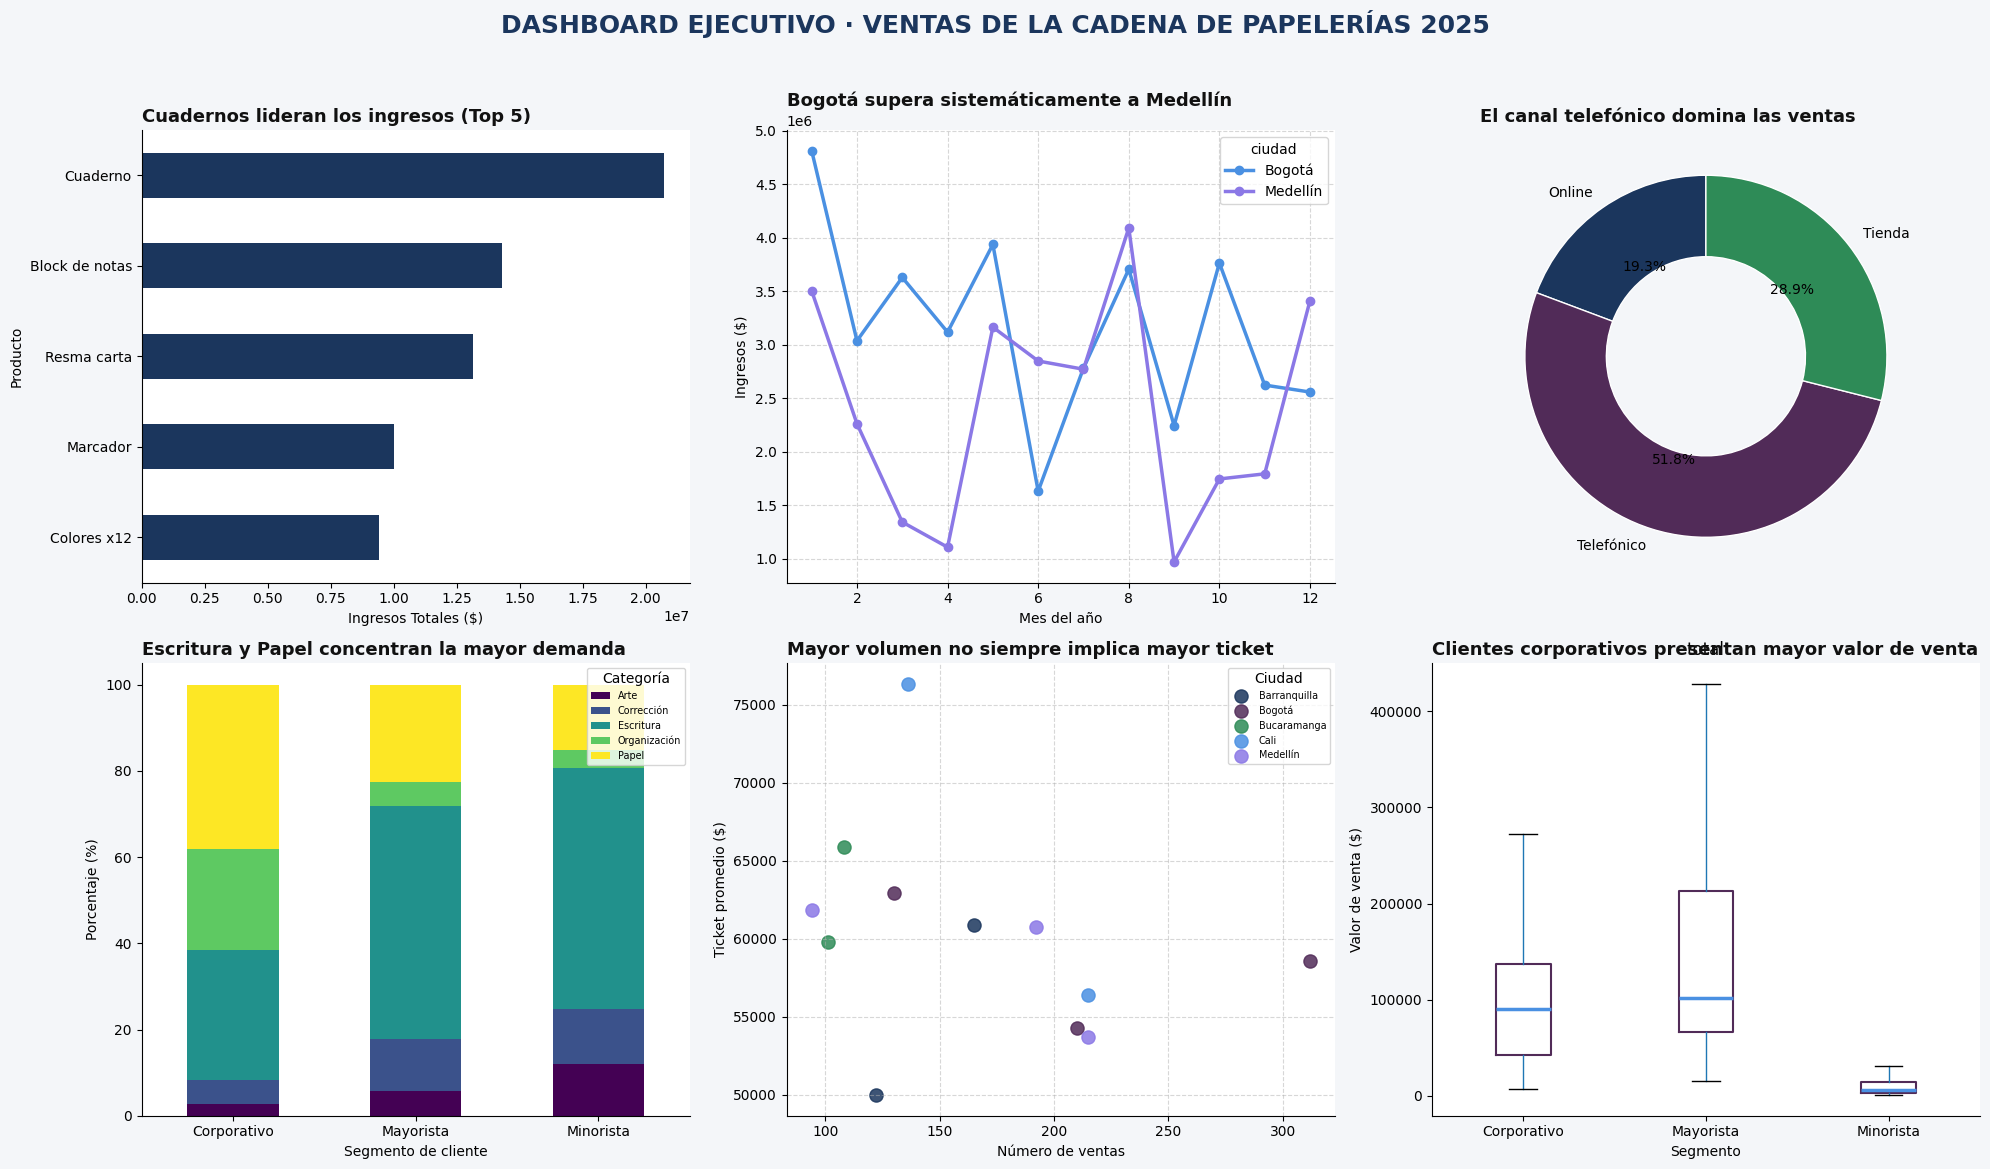

<Figure size 640x480 with 0 Axes>

In [64]:
%run -i figura_base.py

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`) y ejecútalo con el nombre `"v3"`. Tendrás tres versiones para comparar.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# embellecer(prompt_v3, "v3")

In [ ]:
# ✅ Verificación
assert len(VERSIONES) >= 2, "Debes tener al menos dos versiones de tu figura (v1 y v2)"
print("Versiones guardadas:", list(VERSIONES), "· Parte C correcta ✔")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [53]:
figura_elegida = "v2"      # o "v1"

hallazgos = [
    "Bogotá es la ciudad con mayor peso comercial, generando el 31.9 % de los ingresos totales de la cadena durante el 2025.",
    "El canal Telefónico es la principal fuente de ingresos de la empresa, concentrando el 51.8 % de las ventas totales del año.",
    "El Cuaderno es el producto estrella de la cadena, alcanzando ingresos por $ 20.712.345 que representan el 17.5 % de toda la facturación."
]

In [ ]:
# ✅ Verificación
assert figura_elegida in VERSIONES, f"No existe la versión {figura_elegida}: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

In [54]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

KeyError: 'v2'

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook).

Prompt 1 :Mejora el código manteniendo su estructura y funcionalidad, pero optimizando el diseño visual de los gráficos para que tengan una apariencia más profesional y ejecutiva. Utiliza un fondo gris muy claro con paneles blancos y una paleta corporativa moderna, empleando tonos azules para los gráficos de barras y líneas, y colores variados y diferenciados para representar las categorías de productos y los canales de venta. Aplica una tipografía sans-serif, con títulos en negrita, alineados a la izquierda y de tamaño legible. Modifica los títulos de cada gráfico para que sean analíticos y expresen directamente los hallazgos más importantes de los datos, por ejemplo: "Cuadernos lideran los ingresos", "Bogotá supera a Medellín" o "El canal telefónico domina las ventas". Mejora el formato de los ejes y las etiquetas numéricas, incorporando separadores de miles en los valores monetarios y evitando la saturación de información. Elimina los bordes y marcos innecesarios, especialmente los superiores y derechos (spines), incorpora cuadrículas sutiles cuando faciliten la lectura y ajusta la ubicación de las leyendas para que no oculten los datos. Conserva toda la información y precisión de los datos originales, priorizando la claridad, la coherencia visual y una presentación ejecutiva que facilite la interpretación de los resultados comerciales de 2025 y la toma de decisiones estratégicas.

Prompt2: eja todos los datos de los gráficos en diferentes tonos de azules y verdesy deja mas separación entre cada grafica para que se vea mas ordenado. además Haz que el titulo sea mas notorio. Necesito que se vea muy profesional y ordenado.

Tuve que corregir los colores que me daba, le decia mas especificamente que colores queria, tambien corregi el titulo y el funcionamiento del codigo ya que al agregarle las especificaciones del titulo el codigo dejó e funcionar entonces le dije que lo corrigiera.